# 82장 · 데이터 저장·검색

서버를 다시 켰더니 할 일이 사라졌습니다. 이번에는 같은 파일 DB에 다시 연결해 항목을 읽고, ‘50%’처럼 기호가 들어 있는 제목을 정확히 찾습니다. API의 id·title·completed 형태는 81장과 같습니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 다시 연결해 동일한 행 읽기

수업 서버의 PostgreSQL 저장소는 트랜잭션을 커밋한 뒤 저장한 레코드를 돌려줍니다. 여기서는 임시 디렉터리의 SQLite 파일을 사용해 커밋과 새 연결의 차이를 직접 확인합니다. 실제 PostgreSQL 컨테이너는 시작하지 않습니다.

<!-- motion:reopen-database -->
**연결을 닫으면 저장한 할 일도 사라질까요?**

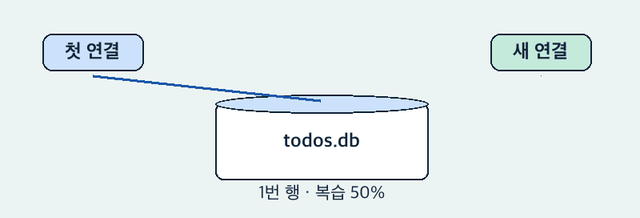

파일 DB에 커밋한 복습 50% 행은 연결 객체를 새로 만들어도 같은 파일에서 읽을 수 있습니다.
<!-- /motion -->


### 셀 01 · 파일 DB에 할 일 저장하기

저장한 행의 ID를 기록합니다. 커널이 살아 있는 동안만 임시 폴더를 유지합니다.

저장 결과가 사라진 것 같으면 파일 경로 → 테이블 존재 → 필터 없는 행 순서로 확인하세요. 새 파일에는 테이블이 없어 조회 오류가 나고, 빈 테이블에는 0행이 있습니다. 원래 파일에서 필터만 풀었을 때 ID 1이 보인다면 행은 남아 있습니다.

In [1]:
import sqlite3
from tempfile import TemporaryDirectory
from pathlib import Path
workspace = TemporaryDirectory()
db_path = Path(workspace.name) / "todos.db"
db = sqlite3.connect(db_path)
with db:
    db.execute("CREATE TABLE todos(id INTEGER PRIMARY KEY, title TEXT, completed INTEGER)")
    created = db.execute("INSERT INTO todos(title, completed) VALUES (?, ?)", ("복습 50%", False))
saved_id = created.lastrowid
db.close()
print(saved_id)

1


새 DB에서 첫 ID 1이 발급됐습니다. 연결은 닫았지만 파일은 지우지 않았습니다.

### 셀 02 · 새 연결을 열고 같은 ID 재조회

두 번째 연결이 같은 파일을 가리키는지 살펴보세요.

In [2]:
db = sqlite3.connect(db_path)
print(db.execute("SELECT id,title,completed FROM todos WHERE id=?", (saved_id,)).fetchone())

(1, '복습 50%', 0)


(1, '복습 50%', 0)이 돌아옵니다. SQLite는 거짓을 0으로 저장합니다. 웹 API가 JSON으로 반환하는 completed는 불리언이어야 합니다.

## %를 제목에 들어 있는 문자로 찾기

검색창에 %를 입력한 사용자는 그 기호가 제목에 들어간 할 일을 찾으려 합니다. PostgreSQL 제공 구현은 strpos로 부분 문자열을 검사합니다. SQLite의 비슷한 함수 instr는 찾은 위치를 1부터 세며, 없으면 0을 돌려줍니다.


### 셀 03 · 일치하는 제목만 선택하기

비교할 일반 제목 한 건을 더 넣은 뒤 검색합니다.

In [3]:
with db:
    db.execute("INSERT INTO todos(title, completed) VALUES (?,?)", ("복습 마무리", True))
matches = db.execute("SELECT title FROM todos WHERE instr(title, ?) > 0 ORDER BY id", ("%",)).fetchall()
print(matches)

[('복습 50%',)]


복습 50% 한 건만 나옵니다. LIKE의 와일드카드로 %를 해석해 전체 목록을 반환하는 실수를 피했습니다. 입력 문자열은 SQL 뒤에 붙이지 않고 별도 인자로 전달합니다.

### 과제 04 · 완료한 항목만 검색하기

‘복습’이 들어가고 완료된 항목의 제목을 오름차순 ID로 조회하세요.

In [4]:
# completed와 instr 조건을 함께 사용하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>sql = &#x27;SELECT title FROM todos WHERE completed=? AND instr(title,?)&gt;0 ORDER BY id&#x27;
print(db.execute(sql, (True, &#x27;복습&#x27;)).fetchall())</code></pre>
<p>실행 결과</p><pre><code>[(&#x27;복습 마무리&#x27;,)]</code></pre>
<p>복습 마무리만 남습니다. 제목 검색과 완료 조건을 각각 통과해야 화면 결과에 들어갑니다.</p>
</details>

## 돌아보기

같은 스키마의 빈 테이블이 있는 다른 DB 파일을 열었을 때와, 원래 DB에서 필터가 모든 행을 제외했을 때를 비교하세요. 연결한 파일 경로, 필터 적용 전 행 수, 필터 적용 후 행 수를 차례로 기록하세요. 테이블도 없는 새 파일에서는 조회할 때 테이블이 없다는 오류가 납니다.